# Step 3: baselines and gap diagnosis
**BT4222 Group 5 · Impression-Aware Re-ranking of Search Results on JD.com**

Sets the bar every later model has to clear, and diagnoses the reference team's model: the hybrid NCF from the previous project's repository (`bt4222-team3-jdsearch`), our prior baseline. One evaluation protocol is fixed here and written to `jd_eval.py`, so step 4 scores its models the same way.

| | |
|---|---|
| **Inputs** | `processed/parquet/` (step 1), `processed/artifacts/` (step 2: features, split, `model_features.json`, `item_features.parquet`) |
| **Outputs** | `processed/artifacts/jd_eval.py` (shared evaluation), `processed/results/step3_results.csv`, `processed/results/per_slate/step3_*.parquet` (per-slate test metrics, for paired comparisons), `processed/results/predictions/step3_*.parquet`, `processed/models/step3_*` |
| **Runtime** | **GPU runtime** (Runtime → Change runtime type → T4). Sections 3 and 4 run on CPU; section 5 trains three neural models. About 3 h 40 min for Run all on a T4: section 5.9 (the three reference-model trainings) takes about 3 h 20 min and section 4 (LightGBM) about 18 min; everything else takes a few minutes. |
| **Next** | `step4_advanced_models.ipynb` imports `jd_eval.py` and compares against `step3_results.csv` |

**How to run.** Run steps 1 and 2 first (with outputs saved), then Runtime → Run all. Each of sections 3, 4 and 5 writes its rows to `step3_results.csv` as it finishes, so if Colab disconnects you can rerun section 0 to 2 and then only the section that did not finish. Set `JD_QUICK=1` in the environment (or `CFG["quick"] = True`) for a smoke test on 5% of users with one epoch.

## What this notebook answers

The deliverable guideline asks for two things here. *Basic:* replicate the prior baseline to obtain comparative metrics. *Advanced:* diagnose its structural failure modes and justify our improvements against them. Every row below is scored on the same users and the same full slates, so differences come from the models, not the evaluation.

| Row | What it is | Why it is here |
|---|---|---|
| Random | Random order within each slate | The floor: any model must beat it |
| Popularity (other users) | Items ranked by how many *other* users' histories hold them | The standard non-personalised baseline. The user's own history is excluded so it measures popularity, not repeat interest |
| Exposure | Items ranked by how many slates show them | The strongest single label-free feature in step 2 (within-slate AUC 0.763) |
| Interim feature set, LightGBM ranker | The 11 features our interim report planned, and the 16 including the ones it dropped | What our own interim plan would have scored, before the history-window finding |
| Reference model, as published | The reference team's hybrid NCF, rebuilt from their notebooks and trained their way | The prior baseline, replicated |
| Reference model, one fix at a time | The same model with each identified failure fixed in turn | The diagnosis: how much each failure costs |

## The evaluation protocol

| Choice | Setting | Why |
|---|---|---|
| Users | The fixed 80/10/10 user split from step 2 (`split_users.parquet`, seed 42). Train fits models, validation chooses epochs and stopping, test is scored once | A user never appears in two splits, so no history or slate leaks across them |
| Slates | The **full** slate JD showed, shuffled in step 1 (mean 89.2 candidates) | The re-ranking task. The reference team trained and tested on slates cut to 1 positive : 4 negatives, mostly 5 to 10 items |
| Ties | Broken at random | Never by list position, which encoded the label in the raw file |
| Gain | 2^label − 1: click 1, cart 3, purchase 7 | Graded, so purchases weigh most, matching the business objective |
| Metrics | NDCG@5, NDCG@10, HR@10 (any engagement in the top 10), purchase recall@10 (share of purchased items placed in the top 10) | NDCG is the headline. Purchase recall checks the conversion objective directly |
| Slates counted | NDCG and HR: slates with at least one positive (1.2% have none). Purchase recall: slates with a purchase | A slate with no positive cannot be ranked better or worse |
| Segments | NDCG@10 within the cold and the warm part of each slate. Cold = the item is in no user's history (as in the interim) | The cold-start question from Part 1. Caveat from step 1: clicks are only kept 7 days, so an item clicked earlier counts as cold |
| Uncertainty | 95% bootstrap intervals over test slates; differences between models are paired by slate | Purchases are rare, so differences need an interval |
| Train performance | The same metrics on a fixed sample of 20,000 training users | The guideline asks for training and testing performance |

## 0. Setup

In [2]:
import os, glob, json, time, random, copy, sys
from contextlib import contextmanager
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
from IPython.display import display, HTML

try:                                   # Colab: mount Drive. Elsewhere: set JD_BASE instead
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

BASE = os.environ.get("JD_BASE", "/content/drive/MyDrive/JDsearch_rawData")   # shared team folder
assert os.path.isdir(BASE), f"{BASE} not found: add a shortcut to JDsearch_rawData in My Drive"
PROC = os.path.join(BASE, "processed")
PATHS = {"parquet": os.path.join(PROC, "parquet"),
         "artifacts": os.path.join(PROC, "artifacts"),
         "features": os.path.join(PROC, "artifacts", "features"),
         "results": os.path.join(PROC, "results"),
         "per_slate": os.path.join(PROC, "results", "per_slate"),
         "predictions": os.path.join(PROC, "results", "predictions"),
         "figures": os.path.join(PROC, "results", "figures"),
         "models": os.path.join(PROC, "models")}
for key in ("results", "per_slate", "predictions", "figures", "models"):
    os.makedirs(PATHS[key], exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)

CFG = {
    "seed": SEED,
    "quick": os.environ.get("JD_QUICK") == "1",   # smoke test: a sample of users, one epoch, few trees
    "user_frac": 1.0,                             # share of users scored and trained on (quick mode lowers it)
    "n_boot": 1000,                               # bootstrap resamples for every interval
    "train_eval_users": 20_000,                   # training users scored to report training performance
    "lgb": {"objective": "lambdarank", "metric": "ndcg", "eval_at": [5, 10], "learning_rate": 0.1,
            "num_leaves": 63, "min_data_in_leaf": 200, "feature_fraction": 0.9, "bagging_fraction": 0.8,
            "bagging_freq": 1, "lambdarank_truncation_level": 20, "verbose": -1, "seed": SEED},
    "lgb_rounds": 1000, "lgb_early_stop": 50,
    # the reference team's settings, read from their notebooks (3.1_Hybrid_NCF_with_LSTM.ipynb)
    "ref": {"emb_dim": 64, "hidden_dim": 128, "max_len": 200, "batch_users": 32, "epochs": 10, "lr": 1e-3,
            "weight_decay": 1e-5, "neg_per_pos": 4, "time_bins": 10, "decay_lambda": 0.02,
            "min_count_full": 2, "eval_batch_users": 256},
}
if CFG["quick"]:
    CFG.update({"user_frac": float(os.environ.get("JD_USER_FRAC", 0.05)), "n_boot": 100, "train_eval_users": 2_000,
                "lgb_rounds": 30})
    CFG["ref"]["epochs"] = 1
print("quick mode" if CFG["quick"] else "full run", "| users used:", f"{CFG['user_frac']:.0%}")

Mounted at /content/drive
full run | users used: 100%


In [3]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
if DEVICE.type != "cuda" and not CFG["quick"]:
    print("WARNING: no GPU. Sections 3 and 4 are fine on CPU, but section 5 will take many hours. "
          "Switch to a GPU runtime before running section 5.")

device: cuda Tesla T4


## 1. Shared helpers and the evaluation module

The evaluation code is written to `processed/artifacts/jd_eval.py` and imported from there, so step 4 imports the same file instead of copying it. Edit it here, not in step 4.

In [ ]:
def parts(prefix, folder="parquet"):
    """Parquet parts from earlier steps. Refuses Drive's duplicate copies (e.g. 'name (1).parquet')."""
    files = sorted(glob.glob(os.path.join(PATHS[folder], f"{prefix}_*.parquet")))
    assert files, f"no {prefix}_*.parquet in {PATHS[folder]}: run the earlier steps first"
    copies = [os.path.basename(f) for f in files if " (" in os.path.basename(f)]
    assert not copies, f"duplicate copies in {PATHS[folder]}: {copies[:3]}. Delete them or rerun that step"
    return files

@contextmanager
def timer(label):
    start = time.time()
    yield
    print(f"[{label}] {time.time() - start:,.1f}s")

def show_result(title, obj=None, note=""):
    """Red RESULT banner, then the table, so key outputs stand out in the saved notebook."""
    extra = f'<div style="font-size:90%;margin-top:3px">{note}</div>' if note else ""
    display(HTML('<div style="border-left:6px solid #c0392b;background:#fbeaea;color:#1f1f1f;'
                 'padding:8px 12px;margin:12px 0 4px 0;font-family:Arial,sans-serif">'
                 f"<b>RESULT</b> &nbsp;|&nbsp; {title}{extra}</div>"))
    if obj is not None:
        display(obj)

def to_int(col):
    """Arrow column of ids (integer or text) -> int64 numpy array, -1 where missing."""
    if pa.types.is_integer(col.type):
        return pc.fill_null(col, -1).to_numpy().astype(np.int64)
    try:
        return pc.fill_null(pc.cast(col, pa.int64()), -1).to_numpy()
    except (pa.ArrowInvalid, pa.ArrowNotImplementedError):
        return pd.to_numeric(col.to_pandas(), errors="coerce").fillna(-1).astype(np.int64).to_numpy()

def flat(t, col):
    """List column -> (all values as one numpy array, list length per user)."""
    return pc.list_flatten(t[col]).to_numpy(), pc.list_value_length(t[col]).to_numpy()

In [ ]:
EVAL_SRC = r'''"""Ranking evaluation shared by steps 3 and 4. Written by step3_baselines.ipynb: edit it there.

Every metric is computed per slate (one user's test query) and then averaged over slates.
Candidates are ranked by score with ties broken at random, never by list position.
Gain is 2**label - 1 (click 1, cart 3, purchase 7).
NDCG and HR are NaN for a slate with no positive; purchase recall is NaN for a slate with no purchase.
"""
import numpy as np
import pandas as pd

METRICS = ["ndcg@5", "ndcg@10", "hr@10", "purchase_recall@10", "ndcg@10_cold", "ndcg@10_warm"]


def per_slate(user, label, score, k=(5, 10), seed=0):
    """One row per slate: NDCG@k for each k, HR@10 and purchase recall@10."""
    user = np.asarray(user, dtype=np.int64)
    label = np.asarray(label, dtype=np.int64)
    score = np.asarray(score, dtype=np.float64)
    cols = ["user_id", "n"] + [f"ndcg@{x}" for x in k] + ["hr@10", "purchase_recall@10"]
    if len(user) == 0:
        return pd.DataFrame(columns=cols)
    tie = np.random.default_rng(seed).random(len(user))
    o = np.lexsort((tie, -score, user))                       # by slate, then score high to low
    u, y = user[o], label[o]
    start = np.r_[0, np.flatnonzero(u[1:] != u[:-1]) + 1]
    n = np.diff(np.r_[start, len(u)])
    rank = np.arange(len(u)) - np.repeat(start, n)            # 0 = top of the slate
    disc = 1.0 / np.log2(rank + 2.0)
    gain = 2.0 ** y - 1.0
    ideal = 2.0 ** y[np.lexsort((-y, u))] - 1.0               # same slates, labels sorted high to low
    total = lambda x: np.add.reduceat(x, start)
    has_pos = total((y > 0).astype(float)) > 0
    out = pd.DataFrame({"user_id": u[start], "n": n})
    for kk in k:
        top = rank < kk
        dcg, idcg = total(gain * disc * top), total(ideal * disc * top)
        out[f"ndcg@{kk}"] = np.where(has_pos, dcg / np.where(idcg > 0, idcg, 1.0), np.nan)
    top10 = rank < 10
    out["hr@10"] = np.where(has_pos, (total(((y > 0) & top10).astype(float)) > 0).astype(float), np.nan)
    n_pur = total((y == 3).astype(float))
    out["purchase_recall@10"] = np.where(n_pur > 0, total(((y == 3) & top10).astype(float))
                                         / np.where(n_pur > 0, n_pur, 1.0), np.nan)
    return out


def evaluate(user, label, score, cold=None, seed=0):
    """per_slate, plus NDCG@10 inside the cold and the warm part of each slate when `cold` is given."""
    df = per_slate(user, label, score, seed=seed)
    if cold is not None:
        user, label, score = np.asarray(user), np.asarray(label), np.asarray(score)
        cold = np.asarray(cold, dtype=bool)
        for name, m in (("cold", cold), ("warm", ~cold)):
            s = per_slate(user[m], label[m], score[m], k=(10,), seed=seed)
            df = df.merge(s[["user_id", "ndcg@10"]].rename(columns={"ndcg@10": f"ndcg@10_{name}"}),
                          on="user_id", how="left")
    return df


def _ci(x, n_boot, rng, chunk=100):
    means = np.empty(n_boot)
    for s in range(0, n_boot, chunk):
        b = min(chunk, n_boot - s)
        means[s:s + b] = x[rng.integers(0, len(x), (b, len(x)))].mean(axis=1)
    return np.quantile(means, [0.025, 0.975])


def summarize(df, metrics=METRICS, n_boot=1000, seed=0):
    """Mean of each metric over slates where it is defined, with a 95% bootstrap interval over slates."""
    rng, out = np.random.default_rng(seed), {}
    for m in metrics:
        if m not in df:
            continue
        x = df[m].to_numpy(dtype=float)
        x = x[~np.isnan(x)]
        if len(x) == 0:
            out.update({m: np.nan, f"{m}_lo": np.nan, f"{m}_hi": np.nan, f"{m}_slates": 0})
            continue
        lo, hi = _ci(x, n_boot, rng)
        out.update({m: x.mean(), f"{m}_lo": lo, f"{m}_hi": hi, f"{m}_slates": len(x)})
    return out


def paired(a, b, metric="ndcg@10", n_boot=1000, seed=0):
    """Mean of (a - b) over the slates both scored, with a paired bootstrap 95% interval."""
    m = a[["user_id", metric]].merge(b[["user_id", metric]], on="user_id", suffixes=("_a", "_b")).dropna()
    d = (m[f"{metric}_a"] - m[f"{metric}_b"]).to_numpy()
    if len(d) == 0:
        return {"diff": np.nan, "lo": np.nan, "hi": np.nan, "slates": 0}
    lo, hi = _ci(d, n_boot, np.random.default_rng(seed))
    return {"diff": d.mean(), "lo": lo, "hi": hi, "slates": len(d)}
'''
with open(os.path.join(PATHS["artifacts"], "jd_eval.py"), "w") as f:
    f.write(EVAL_SRC)
sys.path.insert(0, PATHS["artifacts"])
if "jd_eval" in sys.modules:
    del sys.modules["jd_eval"]
import jd_eval as J

# self-test on a toy slate: a perfect ranking scores 1, the reverse scores less, ties never use list order
_t = J.per_slate([0, 0, 0, 1, 1], [3, 0, 1, 0, 0], [0.9, 0.1, 0.5, 0.3, 0.3])
assert abs(_t.loc[0, "ndcg@10"] - 1) < 1e-12 and np.isnan(_t.loc[1, "ndcg@10"])
_r = J.per_slate([0, 0, 0], [3, 0, 1], [0.1, 0.9, 0.5])
assert _r.loc[0, "ndcg@10"] < 1 and _r.loc[0, "purchase_recall@10"] == 1.0
print("jd_eval written to", os.path.join(PATHS["artifacts"], "jd_eval.py"), "and self-test passed")

jd_eval written to /content/drive/MyDrive/JDsearch_rawData/processed/artifacts/jd_eval.py and self-test passed


In [ ]:
RESULTS_CSV = os.path.join(PATHS["results"], "step3_results.csv")
KEY_COLS = ["model", "scoring", "protocol", "split"]

def record(rows):
    """Add result rows to step3_results.csv, replacing earlier rows with the same model, scoring, protocol, split."""
    new = pd.DataFrame(rows)
    if os.path.exists(RESULTS_CSV):
        old = pd.read_csv(RESULTS_CSV)
        keep = ~old.set_index(KEY_COLS).index.isin(new.set_index(KEY_COLS).index)
        new = pd.concat([old.loc[keep], new], ignore_index=True)
    new.to_csv(RESULTS_CSV, index=False)

def slate_path(model, scoring):
    return os.path.join(PATHS["per_slate"], f"step3_{model}__{scoring}.parquet")

def score_rows(model, label, family, scoring, user, lab, score, cold, split, protocol="full slates", save=False, note=""):
    """Evaluate one scoring of one model on one split and record it; returns the per-slate frame."""
    df = J.evaluate(user, lab, score, cold, seed=SEED)
    row = {"model": model, "label": label, "family": family, "scoring": scoring, "protocol": protocol,
           "split": split, "users": int(len(np.unique(user))), "note": note,
           **J.summarize(df, n_boot=CFG["n_boot"], seed=SEED)}
    record([row])
    if save:
        df.to_parquet(slate_path(model, scoring), index=False)
    return df, row

LADDER_COLS = ["ndcg@5", "ndcg@10", "hr@10", "purchase_recall@10", "ndcg@10_cold", "ndcg@10_warm"]

def fmt_rows(rows):
    """Compact display: each metric as 'mean [lo, hi]' for NDCG@10 and purchase recall, plain means otherwise."""
    t = pd.DataFrame(rows)
    out = t[["label", "scoring", "split"]].copy()
    for m in LADDER_COLS:
        if m in ("ndcg@10", "purchase_recall@10"):
            out[m] = [f"{a:.4f} [{b:.4f}, {c:.4f}]" for a, b, c in zip(t[m], t[f"{m}_lo"], t[f"{m}_hi"])]
        else:
            out[m] = t[m].map(lambda v: f"{v:.4f}")
    return out

## 2. Shared inputs: split, cold flag and feature rows

Every row of step 2's feature files is one impression (user, candidate) of a full, shuffled slate. Sections 3 and 4 read their scores from these rows. Section 5 rebuilds the reference team's own inputs from step 1, because their model reads raw sequences rather than our features.

In [ ]:
# 2.1 Users: the fixed split from step 2, a random subset in quick mode, and the training users scored for train metrics
split = pd.read_parquet(os.path.join(PATHS["artifacts"], "split_users.parquet"))
if CFG["user_frac"] < 1:
    split = split.loc[np.random.default_rng(SEED).random(len(split)) < CFG["user_frac"]]
USERS = {s: np.sort(split.loc[split["split"] == s, "user_id"].to_numpy().astype(np.int64)) for s in ("train", "val", "test")}
TRAIN_EVAL = np.sort(np.random.default_rng(SEED + 1).choice(
    USERS["train"], min(CFG["train_eval_users"], len(USERS["train"])), replace=False))
ACTIVE = np.sort(np.concatenate(list(USERS.values())))
display(pd.Series({s: len(u) for s, u in USERS.items()} | {"train users scored for train metrics": len(TRAIN_EVAL)},
                  name="users").to_frame())

# 2.2 Cold flag: the item is in no user's history (the interim definition; item_features.parquet from step 2)
items = pd.read_parquet(os.path.join(PATHS["artifacts"], "item_features.parquet"), columns=["wid", "i_pop_any"])
_o = np.argsort(items["wid"].to_numpy(), kind="stable")
ITEM_WID, ITEM_POP = items["wid"].to_numpy(np.int64)[_o], items["i_pop_any"].to_numpy()[_o]
del items, _o

def is_cold(wids):
    wids = np.asarray(wids, dtype=np.int64)
    pos = np.clip(np.searchsorted(ITEM_WID, wids), 0, len(ITEM_WID) - 1)
    return ~((ITEM_WID[pos] == wids) & (ITEM_POP[pos] > 0))

,users
train,139075
val,17251
test,17505
train users scored for train metrics,20000


In [ ]:
# 2.3 Feature rows for the users in use, only the columns step 3 reads
with open(os.path.join(PATHS["artifacts"], "model_features.json")) as f:
    MF = json.load(f)
INTERIM, COMPARISON = MF["interim_baseline"], MF["comparison"]
OWN = ["ui_item_days_click", "ui_item_days_cart", "ui_item_days_order"]   # the user's own events on the item
# (the per-row "split" text column is not read: 15.5M strings would cost over a gigabyte of RAM; USERS holds the split)
FE_COLS = list(dict.fromkeys(["user_id", "wid", "label"] + COMPARISON + OWN + ["i_pop_any", "i_exposure_n"]))
with timer("feature rows"):
    frames = []
    for f in parts("features", "features"):
        d = pd.read_parquet(f, columns=FE_COLS)
        frames.append(d.loc[d["user_id"].isin(ACTIVE)])
    FE = pd.concat(frames, ignore_index=True)
    del frames, d
uid = FE["user_id"].to_numpy()
assert (np.diff(uid) >= 0).all(), "feature rows must be grouped by user (step 2 writes them that way)"
FE["cold"] = FE["i_pop_any"].to_numpy() == 0
ROWS = {s: np.flatnonzero(np.isin(uid, u)) for s, u in (("train", TRAIN_EVAL), ("test", USERS["test"]))}
print(f"{len(FE):,} impressions for {len(ACTIVE):,} users | cold share {FE['cold'].mean():.1%}")

[feature rows] 41.1s
15,510,012 impressions for 173,831 users | cold share 56.5%


## 3. Floor baselines

None of these is fitted, so training and test numbers differ only by which users are scored.

* **Random** shows what a ranking with no information scores on these slates.
* **Popularity (other users)** counts the users whose history holds the item, minus the user themselves. Step 2's `i_pop_any` includes the user's own history, and 75% of items appear once, so for many items a popularity of 1 just means "this user touched it". Subtracting it keeps this baseline non-personalised.
* **Exposure** counts the slates the item appears in. It needs no labels and no history.

In [ ]:
# 3.1 Score, evaluate and record the three floors
own = FE[OWN].notna().any(axis=1).to_numpy()
FLOORS = {
    "random": ("Random", lambda d, r: np.random.default_rng(SEED + 7).random(len(r))),
    "pop_other": ("Popularity (other users)", lambda d, r: d["i_pop_any"].to_numpy()[r] - own[r]),
    "exposure": ("Exposure (slates showing the item)", lambda d, r: d["i_exposure_n"].to_numpy()[r]),
}
floor_rows = []
with timer("floors"):
    for key, (label, fn) in FLOORS.items():
        for split_name, r in ROWS.items():
            _, row = score_rows(key, label, "floor", "score", FE["user_id"].to_numpy()[r], FE["label"].to_numpy()[r],
                                fn(FE, r), FE["cold"].to_numpy()[r], split_name, save=(split_name == "test"))
            floor_rows.append(row)
show_result("Floor baselines on full slates", fmt_rows(floor_rows),
            note="Mean over slates, 95% bootstrap interval in brackets for NDCG@10 and purchase recall@10.")

[floors] 14.5s


,label,scoring,split,ndcg@5,ndcg@10,hr@10,purchase_recall@10,ndcg@10_cold,ndcg@10_warm
0,Random,score,train,0.0582,"0.0824 [0.0798, 0.0850]",0.2260,"0.1524 [0.1389, 0.1662]",0.1203,0.1925
1,Random,score,test,0.0562,"0.0800 [0.0771, 0.0828]",0.2193,"0.1263 [0.1129, 0.1402]",0.1231,0.1898
2,Popularity (other users),score,train,0.2932,"0.3440 [0.3390, 0.3488]",0.6480,"0.5906 [0.5707, 0.6110]",0.1171,0.4155
3,Popularity (other users),score,test,0.2918,"0.3423 [0.3372, 0.3477]",0.6458,"0.5979 [0.5770, 0.6187]",0.1213,0.4117
4,Exposure (slates showing the item),score,train,0.2687,"0.3200 [0.3150, 0.3248]",0.6244,"0.5622 [0.5423, 0.5820]",0.2001,0.3966
5,Exposure (slates showing the item),score,test,0.2660,"0.3172 [0.3124, 0.3219]",0.6246,"0.5551 [0.5337, 0.5763]",0.2054,0.3898


## 4. The interim feature set with a LightGBM ranker

What our interim plan would have achieved. `interim_baseline` is the 11 features its re-ranker would have read; `comparison` adds the five it measured and dropped (16). Both come from `model_features.json` and were built in step 2 from the whole pooled history, as the interim defined them; step 2 fixed only the leak in the interaction rate.

LightGBM's LambdaRank objective optimises NDCG directly over each slate, with the same 2^label − 1 gain. Trees are added until validation NDCG@10 stops improving for 50 rounds. Slates with no positive carry no ranking signal and are skipped by the objective.

In [ ]:
import lightgbm as lgb

def lgb_data(users, feats, reference=None):
    r = np.flatnonzero(FE["user_id"].isin(users).to_numpy())
    X = FE[feats].iloc[r].to_numpy(dtype=np.float32)
    y = FE["label"].to_numpy()[r].astype(np.int32)
    _, group = np.unique(FE["user_id"].to_numpy()[r], return_counts=True)   # rows are grouped by user
    cat = [f for f in feats if f == "int_segment27"]
    return lgb.Dataset(X, y, group=group, feature_name=feats, categorical_feature=cat or "auto",
                       reference=reference, free_raw_data=False), r

lgb_rows, LGB_MODELS = [], {}
for key, label, feats in (("interim11_lgb", "Interim feature set (11), LightGBM", INTERIM),
                          ("interim16_lgb", "Interim + dropped features (16), LightGBM", COMPARISON)):
    with timer(f"LightGBM {key}"):
        dtr, _ = lgb_data(USERS["train"], feats)
        dva, _ = lgb_data(USERS["val"], feats, reference=dtr)
        params = dict(CFG["lgb"], eval_at=CFG["lgb"]["eval_at"])
        booster = lgb.train(params, dtr, num_boost_round=CFG["lgb_rounds"], valid_sets=[dva], valid_names=["val"],
                            callbacks=[lgb.early_stopping(CFG["lgb_early_stop"], verbose=False), lgb.log_evaluation(0)])
        booster.save_model(os.path.join(PATHS["models"], f"step3_{key}.txt"))
        LGB_MODELS[key] = booster
        for split_name, r in ROWS.items():
            s = booster.predict(FE[feats].iloc[r].to_numpy(dtype=np.float32), num_iteration=booster.best_iteration)
            _, row = score_rows(key, label, "interim features", "score", FE["user_id"].to_numpy()[r],
                                FE["label"].to_numpy()[r], s, FE["cold"].to_numpy()[r], split_name,
                                save=(split_name == "test"), note=f"{booster.best_iteration} trees")
            lgb_rows.append(row)
            if split_name == "test":
                pd.DataFrame({"user_id": FE["user_id"].to_numpy()[r], "wid": FE["wid"].to_numpy()[r],
                              "label": FE["label"].to_numpy()[r], "score": s}).to_parquet(
                    os.path.join(PATHS["predictions"], f"step3_{key}.parquet"), index=False)
        del dtr, dva
show_result("Interim feature set, LightGBM LambdaRank", fmt_rows(lgb_rows))

imp = pd.DataFrame({k: pd.Series(m.feature_importance("gain"), index=m.feature_name()) for k, m in LGB_MODELS.items()})
imp = (imp / imp.sum()).sort_values("interim16_lgb", ascending=False)
show_result("Share of total split gain per feature", imp.style.format("{:.1%}", na_rep="-"),
            note="Gain shows what the trees used, not what would be lost without it; correlated features share credit.")

[LightGBM interim11_lgb] 619.7s
[LightGBM interim16_lgb] 479.7s


,label,scoring,split,ndcg@5,ndcg@10,hr@10,purchase_recall@10,ndcg@10_cold,ndcg@10_warm
0,"Interim feature set (11), LightGBM",score,train,0.3496,"0.3982 [0.3932, 0.4031]",0.7010,"0.6477 [0.6280, 0.6663]",0.2405,0.4815
1,"Interim feature set (11), LightGBM",score,test,0.3389,"0.3885 [0.3835, 0.3938]",0.6942,"0.6168 [0.5963, 0.6372]",0.2322,0.4681
2,"Interim + dropped features (16), LightGBM",score,train,0.3667,"0.4156 [0.4101, 0.4206]",0.7215,"0.6651 [0.6470, 0.6838]",0.2343,0.4926
3,"Interim + dropped features (16), LightGBM",score,test,0.3587,"0.4071 [0.4024, 0.4125]",0.7161,"0.6613 [0.6424, 0.6807]",0.2301,0.4806


,interim11_lgb,interim16_lgb
i_pop_any,-,60.5%
int_name_sim,20.6%,15.0%
i_eng_rate_oof,42.2%,10.7%
i_exposure_n,22.9%,3.9%
int_recency_log,4.2%,3.4%
int_shop_match,5.1%,3.2%
int_segment27,2.0%,1.2%
int_history_length,1.1%,0.6%
int_brand_match,0.7%,0.4%
int_cate4_match,0.5%,0.3%


## 5. The reference team's model

### 5.0 What we rebuild, and what we change

The model is `SequentialHybridNCF` from the reference team's `3.1_Hybrid_NCF_with_LSTM.ipynb`, trained with their weighted cross-entropy (the run behind their published HR and NDCG). Their inputs come from four earlier notebooks; we rebuild each from our step-1 files.

| Their step | What it does | Here |
|---|---|---|
| Sampling | Keeps every positive plus 4 random negatives per positive. Positives stay first, as in the raw file | Same rule. Our slates were shuffled in step 1, so the negatives are a new random draw (seed 42) and positives are put first in label order, as the raw file had them |
| Product universe | Keeps metadata only for products in the sampled slates (1.26M) | Same |
| History filter | Drops history events whose product is outside that universe (mean history 153 → 66). The time list is filtered with it, so each kept event keeps the gap to the event before it in the *original* history, and the gap to the test query is dropped | Same, including the misaligned gaps |
| User features (15) | Category variety, history length, gap statistics, type ratios, a K-means cluster, time-decay scores, on the filtered history | Same definitions, including their quirks (the last event's gap is skipped as if it were the test query's) |
| Clusters | Median impute → scale → PCA(3) → K-means(4) on 16 features | Same, but fitted on training users only (they fitted on everyone; the features use no labels, so this is hygiene only) |
| Scaling | StandardScaler on all users | Fitted on training users only (same reason) |
| Split | 70/15/15 random users, or random rows in their GRU notebook | Our 80/10/10 user split, so every row of this notebook is scored on the same test users |
| Model | LSTM(2 layers) + attention over history; candidate = sum of 7 embeddings (product, brand, shop, 4 category levels); MLP over [user, candidate, features] → 4 classes | Same code, same sizes, same optimiser, 10 epochs, best epoch by validation loss |

### The failure modes we test

| # | Failure | Evidence in their code | Fix tested here |
|---|---|---|---|
| F1 | **Candidate lookup.** Candidates are indexed with the *history* vocabulary (474k items), but the candidate encoder's brand, shop and category tables are indexed by its *own* vocabulary (1.26M). A warm candidate gets an unrelated product's attributes; every candidate missing from all histories gets index 0, one shared embedding | `NCFDatasetGrouped` maps candidates with the history `wid2idx`; the encoder's lookups were built in `2. Candidate Embedding.ipynb` with a different `wid2idx` | Index each candidate's own row in a full-catalogue attribute table; product embeddings for products seen in training |
| F2 | **Ranking score.** Candidates are sorted by the *largest* class probability, i.e. how confident the model is about any class. A confident "no interaction" ranks first | `user_probs = probs[u].max(dim=1).values` | Rank by expected gain, Σ P(class) × (2^class − 1), which is what NDCG rewards |
| F3 | **Sampled slates.** Trained and tested on 1:4 slates (median 5 items, one positive). HR@5 on a 5-item slate is 1 for any ranking | `Sampling.ipynb`; their test set | Score full slates (all rows); also train on full slates (run 3) |
| F4 | **Ties and list order.** With F1, many candidates share one embedding and so get identical scores. `np.argsort` keeps the list order for short tied arrays, and positives come first in their slates | Sampled slates are never shuffled | Measure: score their sampled test slates as ordered, then shuffled |
| F5 | **Pooled history.** The sequence mixes 7 days of clicks with 90 days of carts and a year of orders (step 1), and the filter drops most of it | Their preprocessing | Not fixable inside this model without redesigning it: this is what step 4 addresses |

Three trainings cover the fixes: **run 1** as published, **run 2** with F1 fixed, **run 3** with F1 fixed and trained on full slates. F2 needs no retraining: every run is scored both ways. F3's test side is covered by scoring every run on full slates.

In [ ]:
# 5.1 Step-1 arrays and the product catalogue
import gc
if "FE" in globals():                      # sections 3 and 4 are done with the feature rows: free the RAM for section 5
    del FE
    gc.collect()
R = CFG["ref"]
T_KEY = 2 ** 31
with timer("step-1 arrays"):
    t = pa.concat_tables([pq.read_table(f, columns=["user_id", "candidate_wids", "candidate_labels", "history_wids",
                                                       "history_types", "history_gaps"]) for f in parts("user_behavior")])
    U = t.num_rows
    assert (t["user_id"].to_numpy() == np.arange(U)).all(), "step-1 user ids are expected to be 0..N-1 in order"
    CW, CN = flat(t, "candidate_wids")
    CW, CL = CW.astype(np.int64), flat(t, "candidate_labels")[0].astype(np.int8)
    HW, HN = flat(t, "history_wids")
    HW, HT, HG = HW.astype(np.int64), flat(t, "history_types")[0].astype(np.int8), flat(t, "history_gaps")[0].astype(np.int64)
    del t
C_OWN, H_OWN = np.repeat(np.arange(U), CN), np.repeat(np.arange(U), HN)

ATTR_COLS = ["brand_id", "shop_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4"]
with timer("product catalogue"):
    t = pa.concat_tables([pq.read_table(f, columns=["wid"] + ATTR_COLS) for f in parts("product_meta")])
    META = {c: to_int(t[c]) for c in ["wid"] + ATTR_COLS}
    _o = np.argsort(META["wid"], kind="stable")
    META = {c: v[_o] for c, v in META.items()}
    del t, _o

def meta_row(wids):
    """0-based row of each product in META, -1 when it has no metadata."""
    wids = np.asarray(wids, dtype=np.int64)
    pos = np.clip(np.searchsorted(META["wid"], wids), 0, len(META["wid"]) - 1)
    return np.where(META["wid"][pos] == wids, pos, -1)

print(f"{U:,} users | {len(CW):,} impressions | {len(HW):,} history events | {len(META['wid']):,} products")

[step-1 arrays] 37.7s
[product catalogue] 46.9s
173,831 users | 15,510,012 impressions | 26,667,260 history events | 12,141,247 products


In [ ]:
# 5.2 Their sampling: every positive, plus 4 random negatives per positive; positives first
pos = CL > 0
npos = np.bincount(C_OWN, weights=pos, minlength=U).astype(np.int64)
order = np.lexsort((np.random.default_rng(SEED).random(len(CW)), -CL, ~pos, C_OWN))   # owner, positives first, label high to low
rank_in_slate = np.arange(len(order)) - np.repeat(np.cumsum(CN) - CN, CN)
keep = pos[order] | ((rank_in_slate - npos[C_OWN]) < R["neg_per_pos"] * npos[C_OWN])
SAMP = order[keep]                       # rows of the flat candidate arrays, in their slate order
del order, rank_in_slate, keep
P = np.unique(CW[SAMP])                  # their product universe
P_META = P[meta_row(P) >= 0]

# their history filter: keep events whose product is in that universe (time list filtered with it)
hkeep = np.isin(HW, P_META)
FH_W, FH_T, FH_G, FH_OWN = HW[hkeep], HT[hkeep], HG[hkeep], H_OWN[hkeep]
FH_N = np.bincount(FH_OWN, minlength=U)
FH_ORD = np.array([0, 1.0, 2.0, 3.0, 1.5])[FH_T]    # their ordinal types: CLICK 1, CART 2, ORD 3, FLW 1.5
sampled_n = np.bincount(C_OWN[SAMP], minlength=U)
show_result("Their sampling and history filter, rebuilt", pd.Series({
    "sampled impressions": f"{len(SAMP):,} ({len(SAMP) / len(CW):.1%} of all)",
    "users with a sampled slate": f"{(sampled_n > 0).sum():,} (empty when the slate has no positive)",
    "sampled slate length: median / mean": f"{np.median(sampled_n[sampled_n > 0]):.0f} / {sampled_n[sampled_n > 0].mean():.1f}",
    "product universe (with metadata)": f"{len(P_META):,}",
    "mean history: before / after the filter": f"{HN.mean():.1f} / {FH_N.mean():.1f}",
    "users left with no history": f"{(FH_N == 0).sum():,}",
}).to_frame("value"), note="Their notebooks report 1,594,553 sampled impressions, 171,728 users, 1,263,429 products, "
                            "history 153.4 → 65.7 and 4,515 users with no history.")

,value
sampled impressions,"1,594,553 (10.3% of all)"
users with a sampled slate,"171,728 (empty when the slate has no positive)"
sampled slate length: median / mean,5 / 9.3
product universe (with metadata),"1,263,951"
mean history: before / after the filter,153.4 / 66.0
users left with no history,"4,520"


In [ ]:
# 5.3 Their 15 user features, on the filtered history, with their definitions
with timer("their user features"):
    end = np.cumsum(FH_N)
    start_h = end - FH_N
    pos_in = np.arange(len(FH_W)) - np.repeat(start_h, FH_N)
    is_last = pos_in == np.repeat(FH_N, FH_N) - 1
    rows_m = meta_row(FH_W)
    n_ = np.maximum(FH_N, 1)
    F = pd.DataFrame(index=pd.RangeIndex(U, name="user_id"))
    for lvl in range(1, 5):                                  # distinct categories per level
        cat = META[f"cate_id_{lvl}"][rows_m]
        ok = cat >= 0
        F[f"nunique_cats_{lvl}"] = np.bincount(np.unique(FH_OWN[ok] * T_KEY + cat[ok]) // T_KEY, minlength=U).astype(float)
    c1_univ = META["cate_id_1"][meta_row(P_META)]            # category sizes over their product universe
    vals, cnt = np.unique(c1_univ, return_counts=True)
    ev_log = np.log10(cnt)[np.clip(np.searchsorted(vals, META["cate_id_1"][rows_m]), 0, len(vals) - 1)]
    F["avg_log_cat_1_popularity"] = np.where(FH_N > 0, np.bincount(FH_OWN, ev_log, minlength=U) / n_, np.nan)
    F["history_len"] = FH_N.astype(float)
    g = FH_G.astype(float)
    nl = ~is_last                                            # they skip the last element as if it were the test query's gap
    F["avg_interaction_time_gap"] = np.where(FH_N >= 2, np.bincount(FH_OWN[nl], g[nl], minlength=U)
                                             / np.maximum(FH_N - 1, 1), np.nan)
    gg = pd.DataFrame({"o": FH_OWN[nl], "g": g[nl]}).groupby("o")["g"]
    ok3 = FH_N >= 3                                          # at least two gaps left after skipping the last
    for name, s in (("std_time_gap", gg.std(ddof=0)), ("min_gap", gg.min()), ("max_gap", gg.max())):
        F[name] = np.where(ok3, s.reindex(np.arange(U)).to_numpy(), np.nan)
    F["total_active_days"] = np.where(ok3, np.bincount(FH_OWN[nl], (g[nl] > 0).astype(float), minlength=U), np.nan)
    for code, name in ((1, "click_ratio"), (2, "cart_ratio"), (3, "order_ratio")):
        F[name] = np.where(FH_N > 0, np.bincount(FH_OWN, (FH_T == code).astype(float), minlength=U) / n_, np.nan)
    cs = np.cumsum(g)                                        # "age": reverse cumulative sum of the filtered gaps
    age = cs[np.repeat(end - 1, FH_N)] - cs + g
    contrib = np.where(nl, FH_ORD * np.exp(-R["decay_lambda"] * age / 86_400), 0.0)
    total = np.bincount(FH_OWN, contrib, minlength=U)
    F["total_time_decay"] = total
    F["avg_time_decay"] = np.where(FH_N >= 2, total / np.maximum(FH_N - 1, 1), 0.0)

    # cluster: median impute -> scale -> PCA(3) -> K-means(4), fitted on training users
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from sklearn.cluster import KMeans
    CLUSTER_FEATS = ["nunique_cats_1", "nunique_cats_2", "nunique_cats_3", "nunique_cats_4", "avg_log_cat_1_popularity",
                     "history_len", "avg_interaction_time_gap", "std_time_gap", "min_gap", "max_gap", "total_active_days",
                     "click_ratio", "cart_ratio", "order_ratio", "total_time_decay", "avg_time_decay"]
    tr_all = np.sort(split.loc[split["split"] == "train", "user_id"].to_numpy())
    imp_ = SimpleImputer(strategy="median").fit(F.loc[tr_all, CLUSTER_FEATS])
    sc_ = StandardScaler().fit(imp_.transform(F.loc[tr_all, CLUSTER_FEATS]))
    Z = sc_.transform(imp_.transform(F[CLUSTER_FEATS]))
    pca_ = PCA(n_components=3, random_state=SEED).fit(Z[tr_all])
    km_ = KMeans(n_clusters=4, random_state=42, init="k-means++", n_init="auto").fit(pca_.transform(Z[tr_all]))
    F["cluster"] = km_.predict(pca_.transform(Z)) + 1

    META_COLS = ["nunique_cats_1", "nunique_cats_2", "nunique_cats_3", "nunique_cats_4", "history_len",
                 "avg_log_cat_1_popularity", "click_ratio", "cart_ratio", "order_ratio", "cluster",
                 "avg_interaction_time_gap", "std_time_gap", "max_gap", "total_time_decay", "avg_time_decay"]
    mf_ = F[META_COLS].fillna(0)
    META_X = StandardScaler().fit(mf_.loc[tr_all]).transform(mf_).astype(np.float32)
    del cs, age, contrib, gg, Z, mf_
show_result("Their 15 user features, rebuilt (training users)", F.loc[tr_all, META_COLS].describe().T.round(2),
            note=f"Cluster sizes (training users): {F.loc[tr_all, 'cluster'].value_counts(normalize=True).sort_index().round(3).to_dict()}")

[their user features] 14.8s


,count,mean,std,min,25%,50%,75%,max
nunique_cats_1,139075.0,8.25,5.99,0.00,3.00,7.00,12.00,34.00
nunique_cats_2,139075.0,13.70,13.08,0.00,4.00,9.00,19.00,118.00
nunique_cats_3,139075.0,19.61,22.17,0.00,5.00,12.00,26.00,262.00
nunique_cats_4,139075.0,21.58,25.89,0.00,5.00,12.00,28.00,335.00
history_len,139075.0,66.19,97.38,0.00,11.00,33.00,82.00,2360.00
avg_log_cat_1_popularity,135458.0,4.69,0.17,2.02,4.60,4.69,4.78,5.01
click_ratio,135458.0,0.32,0.29,0.00,0.05,0.25,0.51,1.00
cart_ratio,135458.0,0.41,0.25,0.00,0.24,0.39,0.57,1.00
order_ratio,135458.0,0.27,0.25,0.00,0.07,0.21,0.42,1.00
cluster,139075.0,2.26,0.90,1.00,2.00,2.00,3.00,4.00


In [ ]:
# 5.4 Their sequence inputs: last 200 filtered events as (product, type, time bin) indices
HIST_VOCAB = np.unique(FH_W)                                  # every product left in any filtered history

def vocab_idx(vocab, wids):
    """1-based position of each product in a sorted vocabulary, 0 when absent."""
    wids = np.asarray(wids, dtype=np.int64)
    if len(vocab) == 0:
        return np.zeros(len(wids), dtype=np.int64)
    pos = np.clip(np.searchsorted(vocab, wids), 0, len(vocab) - 1)
    return np.where(vocab[pos] == wids, pos + 1, 0)

TYPE_VALS = np.unique(FH_ORD)
log_t = np.log1p(FH_G.astype(float))
TIME_BINS = np.round(np.expm1(np.linspace(log_t.min(), log_t.max(), R["time_bins"]))).astype(np.int64)
recent = (np.repeat(FH_N, FH_N) - pos_in) <= R["max_len"]
SEQ = {"w": vocab_idx(HIST_VOCAB, FH_W[recent]), "t": np.searchsorted(TYPE_VALS, FH_ORD[recent]) + 1,
       "s": np.digitize(FH_G[recent], TIME_BINS)}
SEQ_N = np.bincount(FH_OWN[recent], minlength=U)
SEQ_OFF = np.cumsum(SEQ_N) - SEQ_N
del log_t, recent
print(f"history vocabulary {len(HIST_VOCAB):,} | types {TYPE_VALS.tolist()} | time bins {TIME_BINS.tolist()}")

history vocabulary 474,420 | types [1.0, 1.5, 2.0, 3.0] | time bins [0, 6, 45, 315, 2149, 14638, 99681, 678766, 4621935, 31472182]


In [ ]:
# 5.5 Candidate attribute tables: their encoder's (product universe only) and the full catalogue (for the fix)
def code_table(rows):
    """Attribute codes (brand, shop, 4 category levels) for the products at these META rows; row 0 = padding."""
    tab = np.zeros((len(rows) + 1, len(ATTR_COLS)), dtype=np.int32)
    sizes = []
    for j, c in enumerate(ATTR_COLS):
        v = META[c][rows]
        ok = v >= 0
        uniq, inv = np.unique(v[ok], return_inverse=True)
        col = np.zeros(len(rows), dtype=np.int32)
        col[ok] = inv + 1
        tab[1:, j] = col
        sizes.append(len(uniq) + 1)
    return tab, sizes

with timer("attribute tables"):
    TAB_THEIRS, SIZES_THEIRS = code_table(meta_row(P_META))          # row i = P_META[i - 1]
    TAB_FULL, SIZES_FULL = code_table(np.arange(len(META["wid"])))    # row i = META row i - 1
assert len(HIST_VOCAB) <= len(P_META), "their buggy indices must fit their encoder's tables"

# products that get their own embedding: run 2 = their universe; run 3 = seen at least twice in training slates or in a history
tr_rows = np.isin(C_OWN, tr_all)
w_, c_ = np.unique(CW[tr_rows], return_counts=True)
WID_FULL = np.union1d(w_[c_ >= R["min_count_full"]], HIST_VOCAB)
del tr_rows, w_, c_
print(f"their encoder: {len(P_META):,} products | full catalogue: {len(META['wid']):,} | run-3 product embeddings: {len(WID_FULL):,}")

[attribute tables] 20.9s
their encoder: 1,263,951 products | full catalogue: 12,141,247 | run-3 product embeddings: 1,777,850


In [ ]:
# 5.6 Slates as flat arrays, and padded batches
class Slates:
    """Candidates of a set of users: 'sampled' = their 1:4 slates in their order, 'full' = whole shuffled slates."""
    def __init__(self, mode, users, lookup, vocab=None):
        base = SAMP if mode == "sampled" else np.arange(len(CW))
        self.rows = base[np.isin(C_OWN[base], users)]
        own_ = C_OWN[self.rows]
        assert (np.diff(own_) >= 0).all()
        self.users, self.start, self.n = np.unique(own_, return_index=True, return_counts=True)
        w = CW[self.rows]
        if lookup == "buggy":                 # their code: history-vocabulary index into the encoder's tables
            self.attr = self.wid = vocab_idx(HIST_VOCAB, w)
        else:                                 # fix: the product's own catalogue row; own embedding if in `vocab`
            self.attr, self.wid = meta_row(w) + 1, vocab_idx(vocab, w)
        self.label = CL[self.rows].astype(np.int64)
        self.mode, self.lookup = mode, lookup

def pad(flat_arr, off, n, L):
    ar = np.arange(L)
    m = ar[None, :] < n[:, None]
    idx = np.where(m, off[:, None] + ar[None, :], 0)
    return np.where(m, flat_arr[np.clip(idx, 0, max(len(flat_arr) - 1, 0))] if len(flat_arr) else 0, 0), m

def make_batch(S, b):
    users = S.users[b]
    sn = SEQ_N[users]
    L = max(int(sn.max()), 1)
    seq = {k: torch.as_tensor(pad(SEQ[k], SEQ_OFF[users], sn, L)[0], dtype=torch.long, device=DEVICE) for k in SEQ}
    cn = S.n[b]
    C = int(cn.max())
    attr, cm = pad(S.attr, S.start[b], cn, C)
    wid, _ = pad(S.wid, S.start[b], cn, C)
    lab, _ = pad(S.label, S.start[b], cn, C)
    lab = np.where(cm, lab, -1)
    return {"wid_seq": seq["w"], "type_seq": seq["t"], "time_seq": seq["s"],
            "lengths": torch.as_tensor(sn, dtype=torch.long, device=DEVICE),
            "attr_row": torch.as_tensor(attr, dtype=torch.long, device=DEVICE),
            "wid_row": torch.as_tensor(wid, dtype=torch.long, device=DEVICE),
            "meta": torch.as_tensor(META_X[users], device=DEVICE)}, \
           torch.as_tensor(lab, dtype=torch.long, device=DEVICE), cm

### 5.7 The model, as in their notebook

Copied from `3.1_Hybrid_NCF_with_LSTM.ipynb` with one structural change: the candidate encoder takes the attribute row and the product-embedding row as two inputs instead of one. For run 1 both are the same buggy index, which reproduces their behaviour exactly; for runs 2 and 3 they are the product's catalogue row and its embedding row. Everything else (embedding sums, two-layer LSTM with dropout 0.3, attention, the learnable empty-history vector, the MLP with batch norm over all padded candidates) is unchanged.

In [ ]:
class Attention(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.attn = nn.Linear(emb_dim, 1)

    def forward(self, x, mask):
        scores = self.attn(x).squeeze(-1).masked_fill(mask == 0, float("-inf"))
        weights = torch.softmax(scores, dim=1).unsqueeze(-1)
        return (x * weights).sum(dim=1)

class CandidateEncoder(nn.Module):
    """Sum of 7 embeddings: product, brand, shop and 4 category levels (their stage-2 encoder)."""
    def __init__(self, attr_table, n_wid, sizes, emb_dim):
        super().__init__()
        # not saved with the weights: the table is rebuilt from the catalogue (it is 290 MB for the full catalogue)
        self.register_buffer("attr_table", torch.as_tensor(attr_table), persistent=False)
        self.wid_emb = nn.Embedding(n_wid, emb_dim, padding_idx=0)
        self.attr_emb = nn.ModuleList([nn.Embedding(s, emb_dim, padding_idx=0) for s in sizes])

    def forward(self, attr_row, wid_row):
        a = self.attr_table[attr_row].long()
        e = self.wid_emb(wid_row)
        for j, emb in enumerate(self.attr_emb):
            e = e + emb(a[..., j])
        return e

class SequentialHybridNCF(nn.Module):
    def __init__(self, n_items, n_types, n_time_bins, encoder, n_meta, emb_dim=64, hidden_dim=128, n_classes=4):
        super().__init__()
        self.item_emb = nn.Embedding(n_items + 1, emb_dim, padding_idx=0)
        self.type_emb = nn.Embedding(n_types + 1, emb_dim, padding_idx=0)
        self.time_emb = nn.Embedding(n_time_bins + 1, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(input_size=emb_dim, hidden_size=emb_dim, batch_first=True, dropout=0.3, num_layers=2)
        self.attention = Attention(emb_dim)
        self.empty_user_emb = nn.Parameter(torch.zeros(1, emb_dim))
        self.candidate_encoder = encoder
        self.meta_linear = nn.Linear(n_meta, emb_dim)
        self.mlp = nn.Sequential(
            nn.Linear(emb_dim * 3, hidden_dim), nn.ReLU(), nn.BatchNorm1d(hidden_dim), nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim // 2), nn.ReLU(), nn.BatchNorm1d(hidden_dim // 2), nn.Dropout(0.3),
            nn.Linear(hidden_dim // 2, n_classes))

    def encode_user_history(self, wid_seq, type_seq, time_seq, lengths):
        mask = wid_seq != 0
        x = self.item_emb(wid_seq) + self.type_emb(type_seq) + self.time_emb(time_seq)
        batch_emb = self.empty_user_emb.repeat(x.size(0), 1)
        non_empty = lengths > 0
        if non_empty.any():
            packed = pack_padded_sequence(x[non_empty], lengths[non_empty].cpu(), batch_first=True, enforce_sorted=False)
            out, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True)
            batch_emb[non_empty] = self.attention(out, mask[non_empty][:, :out.size(1)])
        return batch_emb

    def forward(self, wid_seq, type_seq, time_seq, lengths, attr_row, wid_row, meta):
        B, C = attr_row.shape
        user = self.encode_user_history(wid_seq, type_seq, time_seq, lengths)
        cand = self.candidate_encoder(attr_row, wid_row)
        meta_e = self.meta_linear(meta)
        fusion = torch.cat([user.unsqueeze(1).expand(-1, C, -1), cand, meta_e.unsqueeze(1).expand(-1, C, -1)], dim=-1)
        return self.mlp(fusion.reshape(B * C, -1)).reshape(B, C, -1)

### 5.8 Training and scoring

As in their notebook: Adam (lr 0.001, weight decay 1e-5), cross-entropy weighted by inverse class frequency in the training slates, gradient clipping at 1, learning rate halved when validation loss stalls for 2 epochs, 10 epochs, and the epoch with the lowest validation loss kept. Validation uses the same slate type the run trains on.

In [ ]:
GAIN = torch.tensor([0.0, 1.0, 3.0, 7.0])

def build_model(run):
    if run["lookup"] == "buggy":
        enc = CandidateEncoder(TAB_THEIRS, len(P_META) + 1, SIZES_THEIRS, R["emb_dim"])
    else:
        enc = CandidateEncoder(TAB_FULL, len(run["vocab"]) + 1, SIZES_FULL, R["emb_dim"])
    torch.manual_seed(SEED)
    return SequentialHybridNCF(len(HIST_VOCAB), len(TYPE_VALS), len(TIME_BINS), enc, META_X.shape[1],
                               R["emb_dim"], R["hidden_dim"]).to(DEVICE)

def mean_loss(model, S, crit):
    model.eval()
    tot, nb = 0.0, 0
    with torch.no_grad():
        for s in range(0, len(S.users), R["eval_batch_users"]):
            x, y, _ = make_batch(S, np.arange(s, min(s + R["eval_batch_users"], len(S.users))))
            m = y != -1
            tot += crit(model(**x)[m], y[m]).item()
            nb += 1
    return tot / max(nb, 1)

def train_run(run, S_tr, S_va):
    model = build_model(run)
    counts = np.bincount(S_tr.label, minlength=4).astype(float)
    w = 1.0 / np.maximum(counts, 1)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w / w.sum(), dtype=torch.float32, device=DEVICE))
    opt = torch.optim.Adam(model.parameters(), lr=R["lr"], weight_decay=R["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
    rng = np.random.default_rng(SEED)
    best, best_state, log = np.inf, None, []
    for epoch in range(R["epochs"]):
        model.train()
        order, tot, nb, t0 = rng.permutation(len(S_tr.users)), 0.0, 0, time.time()
        for s in range(0, len(order), R["batch_users"]):
            b = order[s:s + R["batch_users"]]
            if S_tr.n[b].sum() < 2:          # batch norm needs at least two rows
                continue
            x, y, _ = make_batch(S_tr, b)
            m = y != -1
            loss = crit(model(**x)[m], y[m])
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            tot, nb = tot + loss.item(), nb + 1
        val = mean_loss(model, S_va, crit)
        sched.step(val)
        log.append({"epoch": epoch + 1, "train loss": tot / max(nb, 1), "val loss": val,
                    "lr": opt.param_groups[0]["lr"], "minutes": (time.time() - t0) / 60})
        print(f"  epoch {epoch + 1}: train loss {tot / max(nb, 1):.4f} | val loss {val:.4f} | {log[-1]['minutes']:.1f} min")
        if val < best:
            best, best_state = val, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, pd.DataFrame(log)

def predict(model, S):
    """Class probabilities for every candidate row of S, in S.rows order."""
    model.eval()
    out = np.zeros((len(S.rows), 4), dtype=np.float32)
    with torch.no_grad():
        for s in range(0, len(S.users), R["eval_batch_users"]):
            b = np.arange(s, min(s + R["eval_batch_users"], len(S.users)))
            x, _, cm = make_batch(S, b)
            p = torch.softmax(model(**x), dim=-1).cpu().numpy()
            idx = S.start[b][:, None] + np.arange(cm.shape[1])[None, :]
            out[idx[cm]] = p[cm]
    return out

def their_way(owner, label, score, K):
    """Their HR@K and NDCG@K: np.argsort(-score) per slate in the given row order, gain 2**label - 1,
    ideal over the same K positions, and an ideal of 1 when the slate has no gain."""
    starts = np.r_[0, np.flatnonzero(owner[1:] != owner[:-1]) + 1]
    ends = np.r_[starts[1:], len(owner)]
    hr, nd = np.empty(len(starts)), np.empty(len(starts))
    for i, (a, b) in enumerate(zip(starts, ends)):
        y, s = label[a:b], score[a:b]
        tl = y[np.argsort(-s)[:min(K, b - a)]]
        disc = np.log2(np.arange(2, len(tl) + 2))
        ig = 2.0 ** np.sort(y)[::-1][:len(tl)] - 1
        hr[i] = float((tl > 0).any())
        nd[i] = np.sum((2.0 ** tl - 1) / disc) / (np.sum(ig / disc) if ig.sum() > 0 else 1.0)
    return hr.mean(), nd.mean()

# self-test: with tied scores, their ranking keeps list order, so a positive listed first is "found" at rank 1
_o, _s = np.zeros(5, np.int64), np.full(5, 0.5, np.float32)
assert their_way(_o, np.array([1, 0, 0, 0, 0]), _s, 1) == (1.0, 1.0)
assert their_way(_o, np.array([0, 0, 0, 0, 1]), _s, 1)[0] == 0.0
del _o, _s

def within_slate_shuffle(owner, seed):
    return np.lexsort((np.random.default_rng(seed).random(len(owner)), owner))

def scorings(p):
    return {"max class probability": p.max(axis=1), "expected gain": p @ GAIN.numpy()}

In [ ]:
# 5.9 Three trainings, each scored their way and on our protocol
RUNS = [
    {"key": "ref_published", "label": "Reference model, as published", "train": "sampled", "lookup": "buggy", "vocab": None},
    {"key": "ref_fix_lookup", "label": "Reference model, F1 fixed (lookup)", "train": "sampled", "lookup": "fixed", "vocab": P_META},
    {"key": "ref_fix_full", "label": "Reference model, F1 fixed + full-slate training", "train": "full", "lookup": "fixed", "vocab": WID_FULL},
]
THEIR_WAY, LOGS, REF_ROWS = [], {}, []
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
for run in RUNS:
    print(f"\n=== {run['label']} ===")
    with timer(run["key"]):
        S_tr = Slates(run["train"], USERS["train"], run["lookup"], run["vocab"])
        S_va = Slates(run["train"], USERS["val"], run["lookup"], run["vocab"])
        model, LOGS[run["key"]] = train_run(run, S_tr, S_va)
        torch.save(model.state_dict(), os.path.join(PATHS["models"], f"step3_{run['key']}.pt"))
        del S_tr, S_va

        # their way: sampled test slates, max class probability, as ordered (positives first) and shuffled
        S = Slates("sampled", USERS["test"], run["lookup"], run["vocab"])
        p = predict(model, S)
        own_, lab_ = C_OWN[S.rows], S.label
        mp = p.max(axis=1)
        sh = within_slate_shuffle(own_, SEED)
        ties = pd.Series(mp).groupby([own_, mp]).transform("size").to_numpy() > 1
        prec, rec, f1, _ = precision_recall_fscore_support(lab_, p.argmax(1), average="macro", zero_division=0)
        tw = {"model": run["label"], "accuracy": accuracy_score(lab_, p.argmax(1)), "macro-F1": f1,
              "candidates tied with another in their slate": ties.mean()}
        for K in (5, 10):
            tw[f"HR@{K}"], tw[f"NDCG@{K}"] = their_way(own_, lab_, mp, K)
            tw[f"HR@{K} shuffled"], tw[f"NDCG@{K} shuffled"] = their_way(own_[sh], lab_[sh], mp[sh], K)
        THEIR_WAY.append(tw)
        del S, p

        # our protocol: full slates, both scorings, test users and the training sample
        for split_name, users in (("test", USERS["test"]), ("train", TRAIN_EVAL)):
            S = Slates("full", users, run["lookup"], run["vocab"])
            p = predict(model, S)
            own_, wid_ = C_OWN[S.rows], CW[S.rows]
            cold_ = is_cold(wid_)
            for sc_name, sc in scorings(p).items():
                _, row = score_rows(run["key"], run["label"], "reference model", sc_name, own_, S.label, sc, cold_,
                                    split_name, save=(split_name == "test"))
                REF_ROWS.append(row)
            if split_name == "test":
                pd.DataFrame({"user_id": own_, "wid": wid_, "label": S.label, **{f"p{c}": p[:, c] for c in range(4)}}
                             ).to_parquet(os.path.join(PATHS["predictions"], f"step3_{run['key']}.parquet"), index=False)
            del S, p
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

# random ranking on their sampled test slates, their way, for scale
S = Slates("sampled", USERS["test"], "buggy")
own_, lab_ = C_OWN[S.rows], S.label
rnd = np.random.default_rng(SEED + 7).random(len(own_)).astype(np.float32)
tw = {"model": "Random ranking"}
for K in (5, 10):
    tw[f"HR@{K}"], tw[f"NDCG@{K}"] = their_way(own_, lab_, rnd, K)
THEIR_WAY.append(tw)
pd.DataFrame(THEIR_WAY).to_csv(os.path.join(PATHS["results"], "step3_their_way.csv"), index=False)
pd.concat(LOGS, names=["run"]).to_csv(os.path.join(PATHS["results"], "step3_training_logs.csv"))
del S


=== Reference model, as published ===
  epoch 1: train loss 1.3050 | val loss 1.2750 | 6.0 min
  epoch 2: train loss 1.2781 | val loss 1.2687 | 6.0 min
  epoch 3: train loss 1.2674 | val loss 1.2666 | 5.9 min
  epoch 4: train loss 1.2548 | val loss 1.2654 | 5.9 min
  epoch 5: train loss 1.2396 | val loss 1.2662 | 6.0 min
  epoch 6: train loss 1.2181 | val loss 1.2722 | 6.0 min
  epoch 7: train loss 1.1933 | val loss 1.2772 | 6.0 min
  epoch 8: train loss 1.1129 | val loss 1.3465 | 5.9 min
  epoch 9: train loss 1.0721 | val loss 1.3925 | 5.9 min
  epoch 10: train loss 1.0418 | val loss 1.4353 | 5.9 min
[ref_published] 3,616.0s

=== Reference model, F1 fixed (lookup) ===
  epoch 1: train loss 1.3190 | val loss 1.2752 | 6.3 min
  epoch 2: train loss 1.2664 | val loss 1.2596 | 6.3 min
  epoch 3: train loss 1.2412 | val loss 1.2510 | 6.3 min
  epoch 4: train loss 1.2196 | val loss 1.2434 | 6.3 min
  epoch 5: train loss 1.1981 | val loss 1.2538 | 6.3 min
  epoch 6: train loss 1.1750 | val l

## 6. Results

### 6.1 Reproducing the published numbers

Scored exactly as their notebook did: their 1:4 sampled test slates in their order, ranked by the largest class probability, with their HR and NDCG code. Their saved outputs, weighted cross-entropy run: accuracy 0.5117, macro-F1 0.2890, HR@10 0.9782, NDCG@10 0.5684. (Their code sets K = 5 while the saved output is labelled @10, so the saved cell came from an earlier K; both K are shown.)

In [ ]:
tw = pd.DataFrame(THEIR_WAY) if "THEIR_WAY" in dir() else pd.read_csv(os.path.join(PATHS["results"], "step3_their_way.csv"))
published = pd.DataFrame([{"model": "Published (their notebook, weighted CE)", "accuracy": 0.5117, "macro-F1": 0.2890,
                           "HR@10": 0.9782, "NDCG@10": 0.5684}])
cols = ["model", "accuracy", "macro-F1", "HR@5", "NDCG@5", "HR@10", "NDCG@10", "HR@5 shuffled", "NDCG@5 shuffled",
        "HR@10 shuffled", "NDCG@10 shuffled", "candidates tied with another in their slate"]
tab = pd.concat([published, tw], ignore_index=True).reindex(columns=cols)
show_result("Their evaluation: sampled test slates, ranked by the largest class probability", tab.style.format(
    {c: "{:.4f}" for c in cols if c != "model"} | {"candidates tied with another in their slate": "{:.1%}"}, na_rep="-"),
    note="'Shuffled' scores the same predictions after shuffling each slate, so tied candidates no longer keep "
         "positives first. If shuffling lowers NDCG, part of the published score came from list order (F4).")

,model,accuracy,macro-F1,HR@5,NDCG@5,HR@10,NDCG@10,HR@5 shuffled,NDCG@5 shuffled,HR@10 shuffled,NDCG@10 shuffled,candidates tied with another in their slate
0,"Published (their notebook, weighted CE)",0.5117,0.2890,-,-,0.9782,0.5684,-,-,-,-,-
1,"Reference model, as published",0.5267,0.2978,0.8751,0.5221,0.9796,0.5754,0.8321,0.4214,0.9733,0.4882,50.7%
2,"Reference model, F1 fixed (lookup)",0.3786,0.2438,0.8967,0.5175,0.9874,0.5747,0.8958,0.5062,0.9875,0.5640,17.4%
3,"Reference model, F1 fixed + full-slate training",0.3589,0.2350,0.8869,0.4968,0.9870,0.5568,0.8860,0.4881,0.9868,0.5484,14.0%
4,Random ranking,-,-,0.8990,0.4714,0.9935,0.5329,-,-,-,-,-


### 6.2 Every baseline on our protocol

Full shuffled test slates, the same test users for every row.

In [ ]:
res = pd.read_csv(RESULTS_CSV)
test = res.loc[(res["split"] == "test") & (res["protocol"] == "full slates")].copy()
order_ = ["random", "pop_other", "exposure", "ref_published", "ref_fix_lookup", "ref_fix_full", "interim11_lgb", "interim16_lgb"]
test["o"] = test["model"].map({k: i for i, k in enumerate(order_)})
test = test.sort_values(["o", "scoring"], ascending=[True, False])
show_result("Test performance, full slates", fmt_rows(test.to_dict("records")),
            note="95% bootstrap interval over test slates in brackets. Cold and warm: NDCG@10 within that part of each slate.")
test.drop(columns="o").to_csv(os.path.join(PATHS["results"], "step3_test_table.csv"), index=False)

,label,scoring,split,ndcg@5,ndcg@10,hr@10,purchase_recall@10,ndcg@10_cold,ndcg@10_warm
0,Random,score,test,0.0562,"0.0800 [0.0771, 0.0828]",0.2193,"0.1263 [0.1129, 0.1402]",0.1231,0.1898
1,Popularity (other users),score,test,0.2918,"0.3423 [0.3372, 0.3477]",0.6458,"0.5979 [0.5770, 0.6187]",0.1213,0.4117
2,Exposure (slates showing the item),score,test,0.2660,"0.3172 [0.3124, 0.3219]",0.6246,"0.5551 [0.5337, 0.5763]",0.2054,0.3898
3,"Reference model, as published",max class probability,test,0.0881,"0.1054 [0.1020, 0.1088]",0.2243,"0.2311 [0.2123, 0.2494]",0.1213,0.1520
4,"Reference model, as published",expected gain,test,0.2149,"0.2702 [0.2657, 0.2750]",0.5774,"0.5180 [0.4959, 0.5399]",0.1213,0.3261
5,"Reference model, F1 fixed (lookup)",max class probability,test,0.0873,"0.1150 [0.1117, 0.1181]",0.2722,"0.2458 [0.2272, 0.2637]",0.1125,0.2384
6,"Reference model, F1 fixed (lookup)",expected gain,test,0.1431,"0.1821 [0.1782, 0.1861]",0.4059,"0.3277 [0.3081, 0.3472]",0.1400,0.2785
7,"Reference model, F1 fixed + full-slate training",max class probability,test,0.0770,"0.1030 [0.0999, 0.1062]",0.2486,"0.2117 [0.1946, 0.2294]",0.1102,0.2229
8,"Reference model, F1 fixed + full-slate training",expected gain,test,0.1336,"0.1730 [0.1693, 0.1772]",0.3930,"0.3135 [0.2941, 0.3329]",0.1372,0.2714
9,"Interim feature set (11), LightGBM",score,test,0.3389,"0.3885 [0.3835, 0.3938]",0.6942,"0.6168 [0.5963, 0.6372]",0.2322,0.4681


In [ ]:
# 6.3 Training vs test (same metrics; training = the fixed sample of training users)
tt = res.loc[res["protocol"] == "full slates"].pivot_table(index=["label", "scoring"], columns="split",
                                                           values=["ndcg@10", "purchase_recall@10"])
tt.columns = [f"{m} ({s})" for m, s in tt.columns]
show_result("Training vs test", tt.round(4),
            note="Floors are not fitted, so their gap only reflects which users were scored. A large gap for a fitted "
                 "model means it memorised its training slates.")

ndcg@10 (test)  ndcg@10 (train)  purchase_recall@10 (test)  purchase_recall@10 (train)
label                                           scoring                                                                                                      
Exposure (slates showing the item)              score                          0.3172           0.3200                     0.5551                      0.5622
Interim + dropped features (16), LightGBM       score                          0.4071           0.4156                     0.6613                      0.6651
Interim feature set (11), LightGBM              score                          0.3885           0.3982                     0.6168                      0.6477
Popularity (other users)                        score                          0.3423           0.3440                     0.5979                      0.5906
Random                                          score                          0.0800           0.0824                     0.1263                      0.1524
Reference model, F1 fixed (lookup)              expected gain                  0.1821           0.2214                     0.3277                      0.6946
                                                max class probability          0.1150           0.1428                     0.2458                      0.4925
Reference model, F1 fixed + full-slate training expected gain                  0.1730           0.2076                     0.3135                      0.6952
                                                max class probability          0.1030           0.1272                     0.2117                      0.4834
Reference model, as published                   expected gain                  0.2702           0.2790                     0.5180                      0.6994
                                                max class probability          0.1054           0.1152                     0.2311                      0.3630

### 6.4 What each failure costs

Paired by test slate: the change in NDCG@10 (and purchase recall@10) from one row to the next, with a 95% bootstrap interval. An interval that excludes 0 is a difference the test set can resolve.

In [ ]:
def load_slates(model, scoring):
    p = slate_path(model, scoring)
    return pd.read_parquet(p) if os.path.exists(p) else None

# The best reference variant (run x scoring), chosen on the training-user sample so the test set plays no part
# in the choice. Hardcoding the fully fixed run here mislabelled it as "best" in the first full run.
_tr = res.loc[(res["split"] == "train") & (res["protocol"] == "full slates") & res["model"].str.startswith("ref_")]
_b = _tr.loc[_tr["ndcg@10"].idxmax()]
BEST_REF = (_b["model"], _b["scoring"])
print(f"best reference variant (training-user NDCG@10 {_b['ndcg@10']:.4f}): {_b['label']}, ranked by {_b['scoring']}")

STEPS = [
    ("F2 fixed: rank by expected gain instead of max probability", ("ref_published", "expected gain"), ("ref_published", "max class probability")),
    ("F1 fixed: candidate lookup", ("ref_fix_lookup", "expected gain"), ("ref_published", "expected gain")),
    ("F3 fixed: train on full slates", ("ref_fix_full", "expected gain"), ("ref_fix_lookup", "expected gain")),
    ("All reference fixes vs as published", ("ref_fix_full", "expected gain"), ("ref_published", "max class probability")),
    ("Fully fixed reference model vs popularity", ("ref_fix_full", "expected gain"), ("pop_other", "score")),
    ("Best reference model vs popularity", BEST_REF, ("pop_other", "score")),
    ("Interim features (11) vs best reference model", ("interim11_lgb", "score"), BEST_REF),
    ("Interim features (11) vs popularity", ("interim11_lgb", "score"), ("pop_other", "score")),
    ("Adding the 5 dropped interim features", ("interim16_lgb", "score"), ("interim11_lgb", "score")),
    ("As published vs random", ("ref_published", "max class probability"), ("random", "score")),
]
diffs = []
for name, a, b in STEPS:
    A, B = load_slates(*a), load_slates(*b)
    if A is None or B is None:
        continue
    row = {"comparison": name}
    for m in ("ndcg@10", "purchase_recall@10", "ndcg@10_cold"):
        d = J.paired(A, B, m, n_boot=CFG["n_boot"], seed=SEED)
        row[m] = f"{d['diff']:+.4f} [{d['lo']:+.4f}, {d['hi']:+.4f}]"
        row[f"slates ({m})"] = d["slates"]
    diffs.append(row)
diff_tab = pd.DataFrame(diffs)
diff_tab.to_csv(os.path.join(PATHS["results"], "step3_paired_differences.csv"), index=False)
show_result("Paired differences on test slates (row minus the row it is compared with)", diff_tab)

best reference variant (training-user NDCG@10 0.2790): Reference model, as published, ranked by expected gain


,comparison,ndcg@10,slates (ndcg@10),purchase_recall@10,slates (purchase_recall@10),ndcg@10_cold,slates (ndcg@10_cold)
0,F2 fixed: rank by expected gain instead of max...,"+0.1648 [+0.1604, +0.1694]",17297,"+0.2869 [+0.2658, +0.3057]",2124,"+0.0000 [+0.0000, +0.0000]",4856
1,F1 fixed: candidate lookup,"-0.0881 [-0.0940, -0.0827]",17297,"-0.1903 [-0.2155, -0.1627]",2124,"+0.0186 [+0.0114, +0.0266]",4856
2,F3 fixed: train on full slates,"-0.0090 [-0.0118, -0.0065]",17297,"-0.0142 [-0.0297, +0.0008]",2124,"-0.0027 [-0.0071, +0.0016]",4856
3,All reference fixes vs as published,"+0.0676 [+0.0628, +0.0724]",17297,"+0.0824 [+0.0588, +0.1071]",2124,"+0.0159 [+0.0082, +0.0233]",4856
4,Fully fixed reference model vs popularity,"-0.1693 [-0.1744, -0.1644]",17297,"-0.2844 [-0.3083, -0.2598]",2124,"+0.0159 [+0.0082, +0.0233]",4856
5,Best reference model vs popularity,"-0.0721 [-0.0777, -0.0661]",17297,"-0.0800 [-0.1045, -0.0561]",2124,"+0.0000 [+0.0000, +0.0000]",4856
6,Interim features (11) vs best reference model,"+0.1183 [+0.1119, +0.1245]",17297,"+0.0988 [+0.0714, +0.1278]",2124,"+0.1109 [+0.1016, +0.1201]",4856
7,Interim features (11) vs popularity,"+0.0462 [+0.0421, +0.0505]",17297,"+0.0188 [-0.0025, +0.0395]",2124,"+0.1109 [+0.1016, +0.1201]",4856
8,Adding the 5 dropped interim features,"+0.0186 [+0.0161, +0.0210]",17297,"+0.0445 [+0.0293, +0.0593]",2124,"-0.0022 [-0.0055, +0.0012]",4856
9,As published vs random,"+0.0253 [+0.0213, +0.0292]",17297,"+0.1048 [+0.0825, +0.1279]",2124,"-0.0018 [-0.0097, +0.0055]",4856


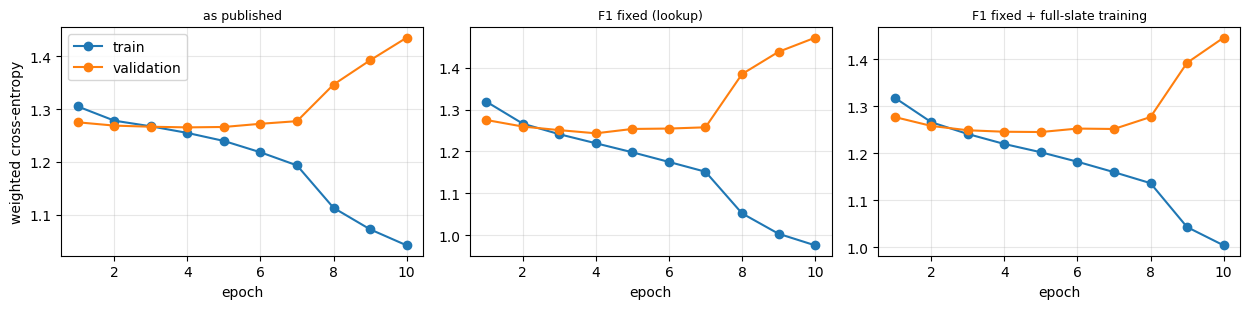

In [ ]:
# 6.5 Training curves of the reference runs
import matplotlib.pyplot as plt
logs = pd.read_csv(os.path.join(PATHS["results"], "step3_training_logs.csv"))
run_keys = list(dict.fromkeys(logs["run"]))
run_labels = dict(zip(res["model"], res["label"]))
fig, axes = plt.subplots(1, len(run_keys), figsize=(4.2 * len(run_keys), 3.2), sharey=False)
for ax, key in zip(np.atleast_1d(axes), run_keys):
    l = logs.loc[logs["run"] == key]
    ax.plot(l["epoch"], l["train loss"], marker="o", label="train")
    ax.plot(l["epoch"], l["val loss"], marker="o", label="validation")
    ax.set_title(run_labels.get(key, key).replace("Reference model, ", ""), fontsize=9)
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("weighted cross-entropy"); np.atleast_1d(axes)[0].legend()
fig.tight_layout()
fig.savefig(os.path.join(PATHS["figures"], "step3_reference_training.png"), dpi=200, bbox_inches="tight")
plt.show()

**Reading the results.**
* **The rebuild is faithful.** Scored their way, our rebuild gets HR@10 0.980 and NDCG@10 0.575 against their published 0.978 and 0.568 (accuracy 0.527 vs 0.512). But random ranking on the same sampled slates already gets NDCG@10 0.533 and HR@10 0.994, so their headline beats random by only 0.04, and HR@10 cannot separate models on 1:4 slates.
* **List order (F4) explains that edge.** 50.7% of candidates are tied with another in their slate, and unshuffled ties keep the raw order, where positives come first. Shuffling the slates drops NDCG@10 from 0.575 to 0.488, below random.
* **On full slates the published model is barely above random.** Test NDCG@10 is 0.105, against 0.080 for random (+0.025 [+0.021, +0.029]) and 0.342 for popularity.
* **Ranking by expected gain (F2) is the only fix that helps:** +0.165 [+0.160, +0.169] NDCG@10 with the same trained model, to 0.270. Fixing the lookup (F1) costs −0.088 [−0.094, −0.083]: with the bug every unseen item shares one embedding that works as an accidental popularity flag, and per-item embeddings memorise training users instead (purchase recall@10 0.695 on training users, 0.328 on test). Training on full slates (F3) costs −0.009. Only F1 helps cold items, by +0.019; the published model scores every cold item in a slate the same, so its cold NDCG equals popularity's (0.121).
* **The bar.** The best reference variant (chosen on training users: as published, ranked by expected gain) is 0.072 [0.066, 0.078] below popularity. The interim feature set with LightGBM gets 0.389 (+0.118 over the best reference model), and adding back the 5 dropped interim features gives **0.407**, the bar step 4 must clear. Cold items are where most room is left: 0.230 against 0.481 for warm.


## 7. Outputs of this notebook

In [4]:
for folder in ("results", "per_slate", "predictions", "models"):
    for f in sorted(glob.glob(os.path.join(PATHS[folder], "step3_*"))):
        print(f"{os.path.relpath(f, BASE):<70} {os.path.getsize(f) / 1e6:>9,.1f} MB")
print(f"{os.path.relpath(os.path.join(PATHS['artifacts'], 'jd_eval.py'), BASE):<70}")

processed/results/step3_paired_differences.csv                               0.0 MB
processed/results/step3_results.csv                                          0.0 MB
processed/results/step3_test_table.csv                                       0.0 MB
processed/results/step3_their_way.csv                                        0.0 MB
processed/results/step3_training_logs.csv                                    0.0 MB
processed/results/per_slate/step3_exposure__score.parquet                    0.2 MB
processed/results/per_slate/step3_interim11_lgb__score.parquet               0.2 MB
processed/results/per_slate/step3_interim16_lgb__score.parquet               0.2 MB
processed/results/per_slate/step3_pop_other__score.parquet                   0.2 MB
processed/results/per_slate/step3_random__score.parquet                      0.2 MB
processed/results/per_slate/step3_ref_fix_full__expected gain.parquet        0.2 MB
processed/results/per_slate/step3_ref_fix_full__max class probability.parque

## 8. AI interaction log
*Record essential exchanges as you go; they are merged into the report appendix.*

| # | Core prompt and task objective | AI output summary | Critical evaluation | Refinement and final action |
|---|---|---|---|---|
| 1 | "As you know we are using the models in the github repo as the baseline. According to the final deliverables document, what is the next step?" | It pointed to Aspect 2 (baseline benchmarking and gap diagnosis) and said to fix the evaluation protocol first, because every later model reuses it: our 80/10/10 user split, full shuffled slates, graded NDCG@5/10 with gain 2^label − 1, purchase recall@10, cold and warm items separately, bootstrap intervals. Then add random and popularity floors, replicate the reference model as published, and fix its faults one at a time | The reference team's 0.57 NDCG@10 looked strong until we saw it was measured on 1:4 sampled slates, where a random order also scores well. Without floors on the same slates, no number in their report or ours could be read | We wrote the protocol once, to `jd_eval.py`, so step 4 imports the same metrics, and scored every model on the same test users. The floors became the first rows of the results table |
| 2 | "It's been running, can you check on the results?" | It read the saved outputs mid-run. Popularity alone gets NDCG@10 0.342, more than 4 times random, and adding back the 5 features the interim dropped raises LightGBM from 0.389 to 0.407. On full slates the published reference model gets 0.105, and ranking the same model by expected gain instead of the largest class probability lifts it to 0.270 | A model that looks poor on our protocol could just be a bad rebuild, so we checked the rebuild against their published numbers first: 0.575 vs 0.568 NDCG@10 and 0.980 vs 0.978 HR@10. Only then is it fair to say their model, not our copy of it, is weak | We report the reference model on both protocols: their way, with random on the same slates (0.533) and the shuffled-slate drop to 0.488, and on full slates beside the floors |
| 3 | "Check again" (runs 1 and 2 had finished: fixing the lookup bug lowered NDCG@10 from 0.270 to 0.182) | It explained that with the bug every item outside the history vocabulary shares one embedding, which the model learns to push down, so the bug works as an accidental popularity flag. With the fix each item gets its own embedding, and sampled training sees too few impressions per item to learn them; purchase recall@10 is 0.695 on training users and 0.328 on test users | A correct fix that lowers the score is still a finding: it shows the reference model's item signal was mostly popularity, and that its embeddings memorise users. Training on full slates (10 times more data) also cost −0.009, so data quantity is not the bottleneck | We kept all three fixes in the table as one-change-at-a-time comparisons with paired intervals, and report F1 as correct but harmful, with its cold-item gain (+0.019) |
| 4 | "Section 6 is done" | It found its own bug: the "best reference model" rows were hardcoded to the fully fixed run (0.173 NDCG@10), but the best variant is the published model ranked by expected gain (0.270). With the wrong model the comparisons read −0.169 vs popularity and +0.216 for the interim LightGBM | Hardcoding the "best" model after seeing results is a selection made by hand, and choosing it on test scores would leak the test set into the comparison. The AI's own code needed the same checking as anyone's | Section 6.4 now picks the best variant by NDCG@10 on the training-user sample (0.279), so the test set plays no part. The corrected rows are −0.072 [−0.078, −0.066] vs popularity and +0.118 [+0.112, +0.125] for the interim LightGBM, and the fully fixed run keeps its own labelled row |
| 5 | "What is the issue? I tried running Section 7" (NameError: name 'glob' is not defined) | It explained that the Colab session had restarted, so section 0's imports and paths were gone, and section 7 depends on them | Each section reads its inputs from Drive, but every cell still needs section 0 run first in a fresh session | We ran section 0 and then section 7, which listed every output file. The "How to run" note already says to rerun sections 0 to 2 after a disconnect |
